# 02 · Module 1: intensity-aware and directional 1D–2D agreement

**Research question 1.** Do the 1D signal CNN and the 2D image CNN explain the same recording with the same temporal evidence, and is their agreement above chance?

**Method.** Both Grad-CAM maps are placed on one 600-column time grid (536 valid waveform columns).
The 2D map is projected onto the waveform with an explicit kernel that weights but never replaces its intensity,
$g_2(u)=\sum_y H(y,u)K(y,u)/\sum_y K(y,u)$, here an on-trace corridor of $\pm 6$ px (the projection used by Modules 2 and 3).
Each map is normalised to attribution mass, $p_u=g_1(u)/\sum g_1$, $q_u=g_2(u)/\sum g_2$, and compared with

* shared mass $O=\sum_u \min(p_u,q_u)$, weighted Jaccard $J_w=O/(2-O)$, total variation $1-O$,
* Spearman $\rho_s$, top-15 % Dice (chance level $k/T=0.15$),
* direction $r_u=(p_u-q_u)/(p_u+q_u)$, gated $|r_u|>1/3$ (one branch carries at least twice the mass) on the union of salient columns,
* normalised entropy of each map (1 = flat).

Every statistic is compared with a **within-class mispairing null**: the 1D map of one recording is paired with the 2D map of another recording of the same class.

**Module 1 branch analysis.** Section 5 reproduces the min–max agreement analysis of the Module 1 branch (`module1-nahida`) on all 1054 recordings: local agreement $A(u)=\sqrt{\hat g_1\hat g_2}$ and disagreement $D(u)=|\hat g_1-\hat g_2|$ of min–max-normalised profiles, class-wise statistics, the correctness subgroups, and the alignment-shift, projection-mask and temporal-validation sensitivity analyses.

> **Code on GitHub.** The re-run of the MM-GradCAM anchor (cohort, frozen split, 1D/2D CNN training and test-split manifests) is on the `main` branch of <https://github.com/dwiharyani/dan-mmgradcam-anchor-replication>. The Grad-CAM temporal alignment and the Module 1 alignment code are on the `module1-nahida` branch of the same repository. The same scripts are also included in `src/hpc_pipeline/` of the submitted package.

> **Google Colab:** upload `DAN-MMGradCAM_COE691.zip` (Files panel), then run `!unzip -q DAN-MMGradCAM_COE691.zip -d /content` once in a code cell. The setup cell below finds the folder automatically. **Jupyter:** open this notebook from the `notebooks/` folder of the extracted package.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

def find_root():
    """Repository root: works from notebooks/, from the root itself, and in Google Colab (/content)."""
    here = Path.cwd().resolve()
    for p in [here, *here.parents, Path('/content/DAN-MMGradCAM'), Path('/content/drive/MyDrive/DAN-MMGradCAM')]:
        if (p / 'data' / 'archived').is_dir() and (p / 'src').is_dir():
            return p
    raise FileNotFoundError('DAN-MMGradCAM folder not found. In Colab, upload DAN-MMGradCAM_COE691.zip and run: '
                            '!unzip -q DAN-MMGradCAM_COE691.zip -d /content')
ROOT = find_root()                          # repository root
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


In [2]:
from scipy.stats import spearmanr, kruskal
EPS, TOP, GATE, N_NULL, N_BOOT, SEED = 1e-12, 0.15, 1/3, 20, 2000, 20261117
rng = np.random.default_rng(SEED)

def mass(x):
    x = np.clip(np.nan_to_num(np.asarray(x, float)), 0, None); s = x.sum()
    return None if s <= EPS else x / s

def topk(x, f):
    k = max(1, int(np.ceil(f * x.size))); s = np.zeros(x.size, bool)
    s[np.argsort(-x, kind='stable')[:k]] = True; return s

def entropy_norm(p):
    nz = p[p > 0]; return float(-(nz * np.log(nz)).sum() / np.log(p.size))

def agreement(p, q):
    """Module 1 agreement between two attribution-mass vectors on the same time grid."""
    O = float(np.minimum(p, q).sum()); a, b = topk(p, TOP), topk(q, TOP)
    r = (p - q) / (p + q + EPS); sal = a | b
    return {'O': O, 'Jw': O / (2 - O), 'TV': 1 - O, 'spearman': float(spearmanr(p, q).statistic),
            'dice15': 2 * (a & b).sum() / (a.sum() + b.sum()), 'chance_dice': a.sum() / p.size,
            'dir_1D_dominant': 100 * np.mean(sal & (r > GATE)), 'dir_2D_dominant': 100 * np.mean(sal & (r < -GATE)),
            'dir_balanced': 100 * np.mean(sal & (np.abs(r) <= GATE)),
            'entropy_1D': entropy_norm(p), 'entropy_2D': entropy_norm(q)}

def boot_ci(x, stat=np.median):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    b = [stat(rng.choice(x, x.size)) for _ in range(N_BOOT)]
    return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

## 1. Per-recording agreement

In [3]:
z = np.load(ARCH / 'module2/noise_stability_maps.npz')
rec = pd.read_csv(ARCH / 'module2/noise_stability_records.csv')
assert (rec.cohort_index.to_numpy() == z['cohort_index']).all()
V = z['valid_600'].astype(bool)
rec['both_correct'] = (rec.pred_1d == rec.class_name) & (rec.pred_2d == rec.class_name)
rows, P, Q = [], {}, {}
for i, r in rec.iterrows():
    p, q = mass(z['base1'][i][V[i]]), mass(z['base2'][i][V[i]])
    if p is None or q is None:
        rows.append({'cohort_index': r.cohort_index, 'class_name': r.class_name, 'degenerate': True}); continue
    P[i], Q[i] = p, q
    rows.append({'cohort_index': r.cohort_index, 'class_name': r.class_name, 'degenerate': False,
                 'both_correct': r.both_correct, **agreement(p, q)})
per = pd.DataFrame(rows)
per.to_csv(TAB / 'module1_per_record.csv', index=False)
prim = per[(~per.degenerate) & (per.both_correct == True)]
print('valid columns per record:', V[0].sum(), '| degenerate maps:', int(per.degenerate.sum()), '| primary cohort:', len(prim))
prim.drop(columns=['degenerate', 'both_correct']).describe().T[['mean', '25%', '50%', '75%']].round(3)

valid columns per record: 536 | degenerate maps: 0 | primary cohort: 939


,mean,25%,50%,75%
cohort_index,546.087,265.500,519.000,778.500
O,0.416,0.355,0.421,0.479
Jw,0.266,0.216,0.267,0.315
TV,0.584,0.521,0.579,0.645
spearman,0.076,0.002,0.071,0.149
dice15,0.173,0.111,0.160,0.222
chance_dice,0.151,0.151,0.151,0.151
dir_1D_dominant,12.596,11.754,12.687,13.433
dir_2D_dominant,9.988,8.582,10.075,11.381
dir_balanced,5.028,3.545,4.851,6.343


## 2. Within-class mispairing null

In [4]:
null = []
for c in CLASSES:
    idx = np.array([i for i in P if rec.class_name[i] == c and rec.both_correct[i]])
    for _ in range(N_NULL):
        for i, j in zip(idx, rng.permutation(idx)):
            if i != j:
                m = agreement(P[i], Q[j]); null.append({'class_name': c, 'O': m['O'], 'spearman': m['spearman'], 'dice15': m['dice15']})
null = pd.DataFrame(null); null.to_csv(TAB / 'module1_null_mispairing.csv', index=False)
print('mispaired 1D/2D pairs in the null:', len(null))

mispaired 1D/2D pairs in the null: 18687


In [5]:
m1 = []
for c in CLASSES + ['ALL']:
    g = prim if c == 'ALL' else prim[prim.class_name == c]
    nn = null if c == 'ALL' else null[null.class_name == c]
    row = {'class': c, 'n': len(g)}
    for k in ['O', 'Jw', 'spearman', 'dice15', 'entropy_1D', 'entropy_2D', 'dir_1D_dominant', 'dir_2D_dominant', 'dir_balanced']:
        row[k] = g[k].median()
    for k in ['O', 'spearman', 'dice15']:
        row[f'{k}_CI'] = '%.3f–%.3f' % boot_ci(g[k]); row[f'{k}_null'] = nn[k].median()
    thr = {cc: null[null.class_name == cc]['O'].quantile(.95) for cc in CLASSES}
    row['% records O > null95'] = 100 * np.mean([o > thr[cl] for o, cl in zip(g.O, g.class_name)])
    row['% records 2D-leaning'] = 100 * (g.dir_2D_dominant > g.dir_1D_dominant).mean()
    m1.append(row)
m1 = pd.DataFrame(m1); m1.to_csv(TAB / 'module1_agreement_by_class.csv', index=False)
kw = kruskal(*[prim[prim.class_name == c].O for c in CLASSES])
print(f'Kruskal-Wallis test of shared mass across classes: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}')
m1.set_index('class').T

Kruskal-Wallis test of shared mass across classes: H = 137.9, p = 1.07e-29


class,AFib,GSVT,SB,SR,ALL
n,208,196,366,169,939
O,0.4187,0.4461,0.3811,0.4742,0.4212
Jw,0.2648,0.2871,0.2354,0.3108,0.2668
spearman,0.0682,0.0374,0.057,0.1487,0.0713
dice15,0.1852,0.1481,0.1481,0.1852,0.1605
entropy_1D,0.8498,0.8657,0.8218,0.8707,0.8486
entropy_2D,0.9681,0.9779,0.978,0.9753,0.9753
dir_1D_dominant,12.4067,12.6866,13.0597,12.3134,12.6866
dir_2D_dominant,10.0746,9.8881,10.8209,9.1418,10.0746
dir_balanced,5.0373,5.4104,4.1045,6.1567,4.8507


**Reading.** The median shared mass of correctly paired recordings is only slightly higher than that of mispaired recordings of the same class,
rank correlation is close to zero, and Dice is close to its chance value 0.15. The 2D map is nearly flat (normalised entropy ≈ 0.97),
and among salient columns 2D-dominant time is more common than 1D-dominant time.

## 3. Case study and cohort figure

ECG 209 (MUSE_20180113_182321_68000.csv): O recomputed from the maps = 0.287
    O    Jw  spearman  dice15  dir_1D_dominant  dir_2D_dominant
0.287 0.167     0.062    0.37             12.5            9.142
saved fig_module1_case209_drawn
saved col_module1_case209


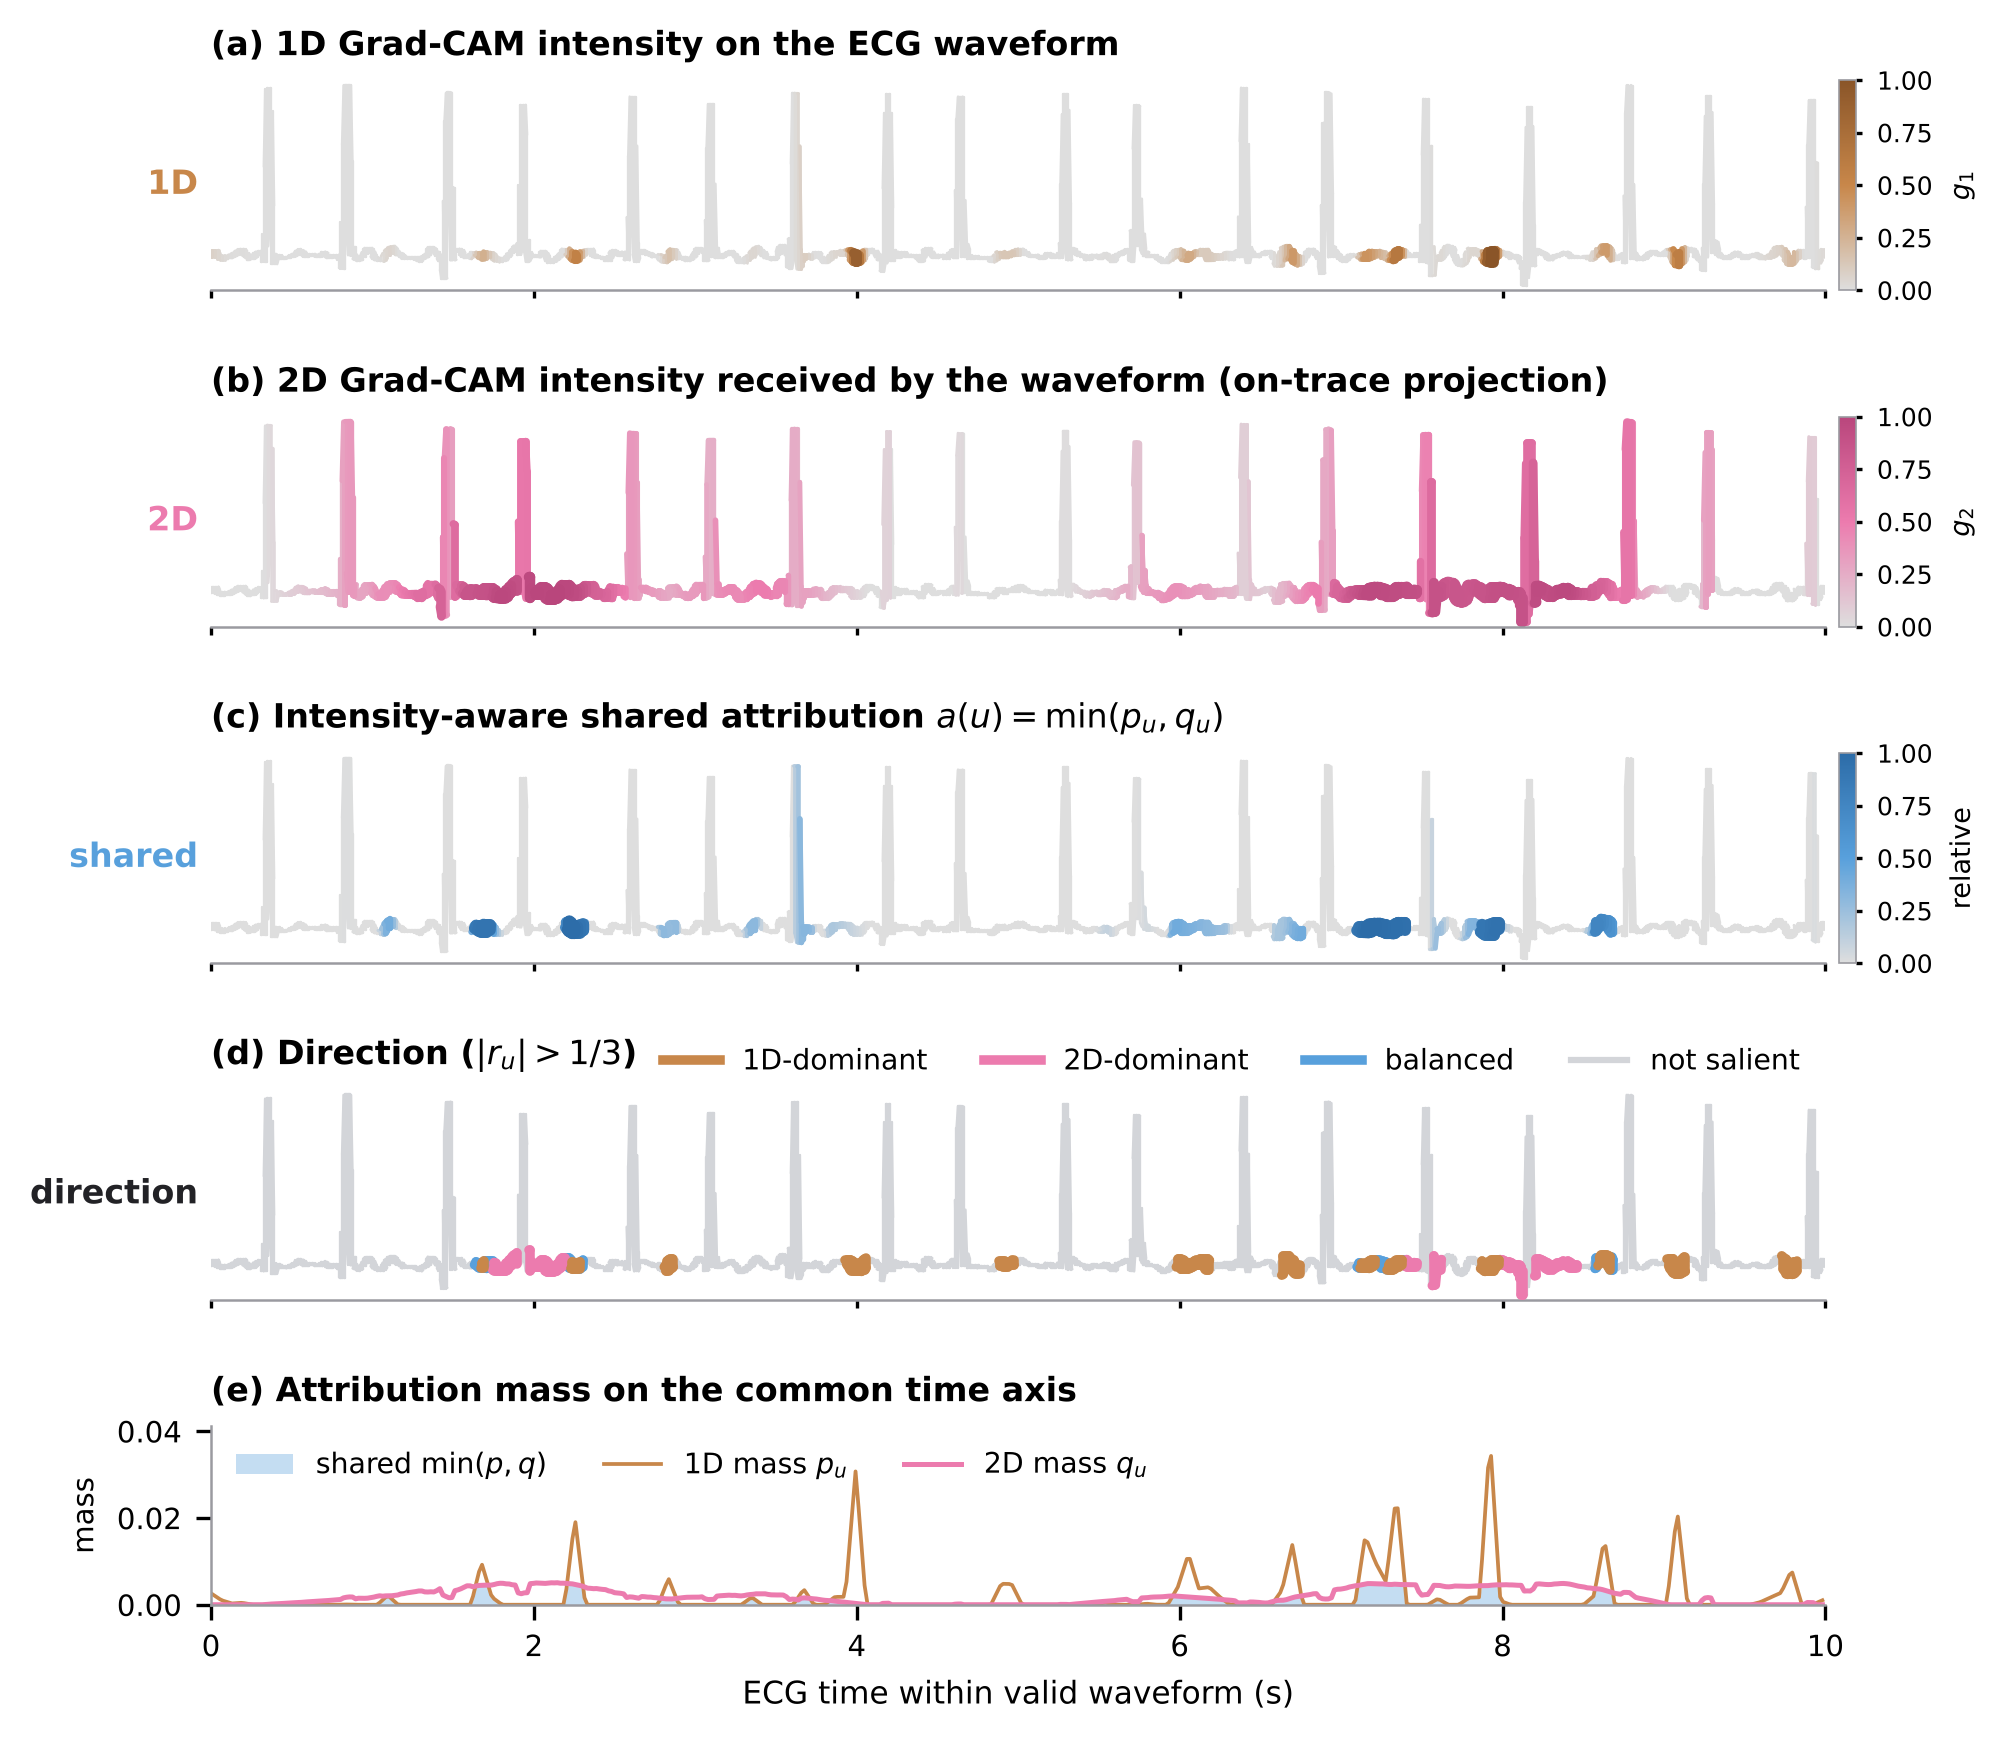

In [6]:
import dan_figures as F
z_m = np.load(ARCH / 'module2/noise_stability_maps.npz')        # archived Grad-CAM maps (HPC run); base1/base2 = unperturbed ECG
mask209 = np.load(ARCH / 'module1/ecg209_trace_mask.npy')       # pixel mask of the ECG 209 waveform (drawing background only)
i209 = int(np.flatnonzero(z_m['cohort_index'] == 209)[0])
v = z_m['valid_600'][i209].astype(bool)
p209, q209 = F.mass(z_m['base1'][i209][v]), F.mass(z_m['base2'][i209][v])
print(f'ECG 209 ({z_m["filename"][i209]}): O recomputed from the maps = {np.minimum(p209, q209).sum():.3f}')
print(per[per.cohort_index == 209][['O', 'Jw', 'spearman', 'dice15', 'dir_1D_dominant', 'dir_2D_dominant']].round(3).to_string(index=False))
F.fig_case_module1(z_m, i209, mask209, FIG)
import dan_column_figures as C
C.fig_module1_case_column(z_m, i209, mask209, FIG)   # single-column version used in the report
show('fig_module1_case209_drawn', 900)

ECG 209 (AFib), drawn from the archived Grad-CAM maps of the unperturbed recording (`base1`, `base2` in `noise_stability_maps.npz`, written by
`src/hpc_pipeline/03_module2_stability/module2_common.py`): (a) aligned 1D intensity on the waveform; (b) 2D intensity received by the waveform inside the ±6 px corridor;
(c) shared intensity $\min(p,q)$; (d) direction among salient columns; (e) the two mass curves. Grad-CAM is not re-run here; panels (c)–(e) and $O$ are computed from the maps in this cell.

saved fig_module1_cohort


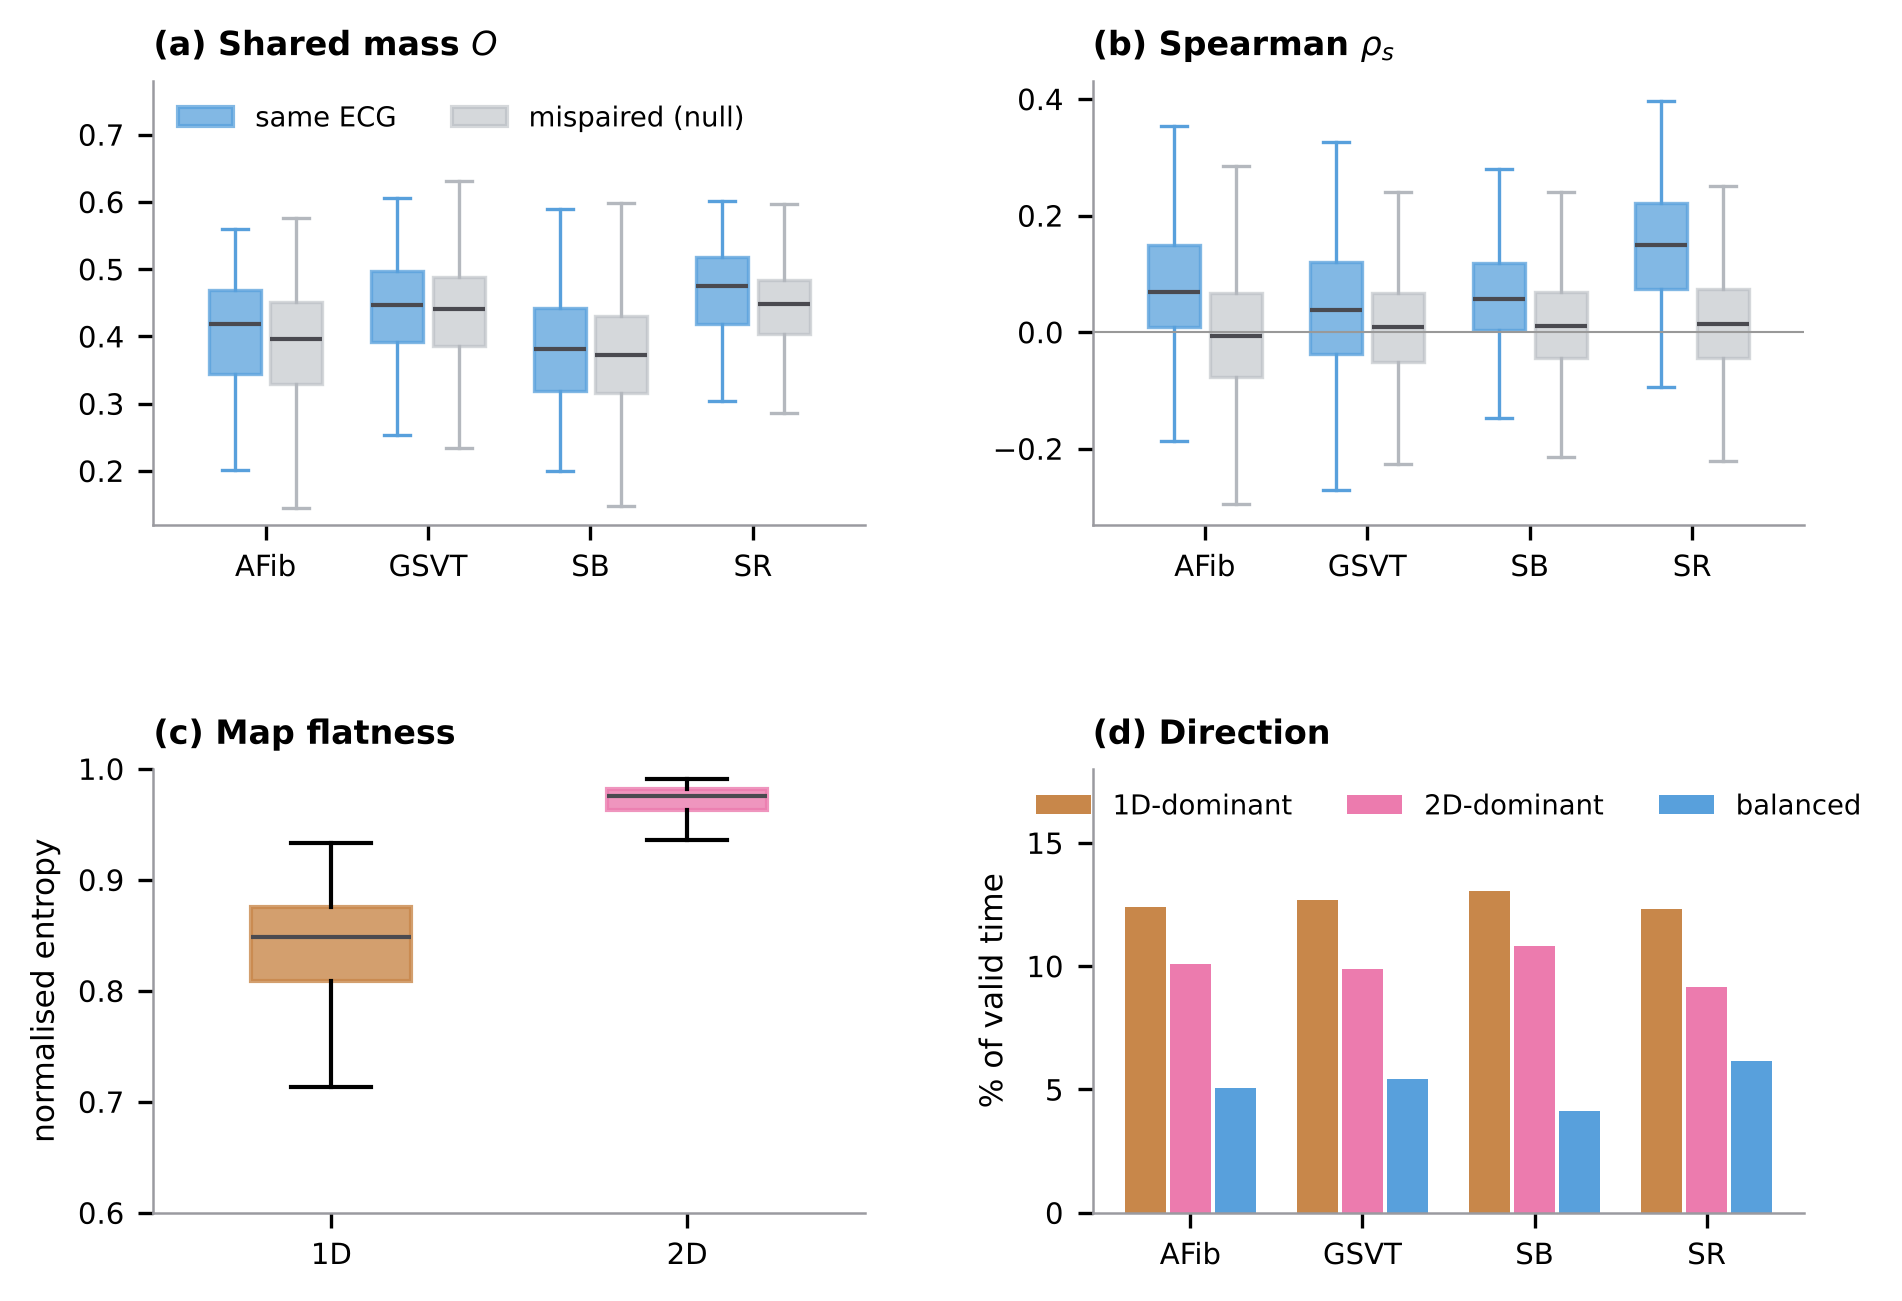

In [7]:
import dan_figures as F
per_fig = per.copy(); per_fig['both_correct'] = per_fig.both_correct.fillna(False).astype(bool)
F.fig_module1_cohort(per_fig, null, FIG)
show('fig_module1_cohort', 700)

## 4. Comparison with the anchor-style binary-mask agreement and projection sensitivity

The Module 1 branch computes agreement after min–max scaling each projected map (Section 5).
Below, the same recordings are summarised with that measure next to the mass-based agreement of this notebook.

,method,n,median weighted Jaccard,median Spearman,median Dice top-15%
0,min–max agreement (Module 1 branch),1033,0.154,0.090,0.173
1,intensity-aware mass (this work),939,0.267,0.071,0.160


saved fig_module1_minmax_baseline


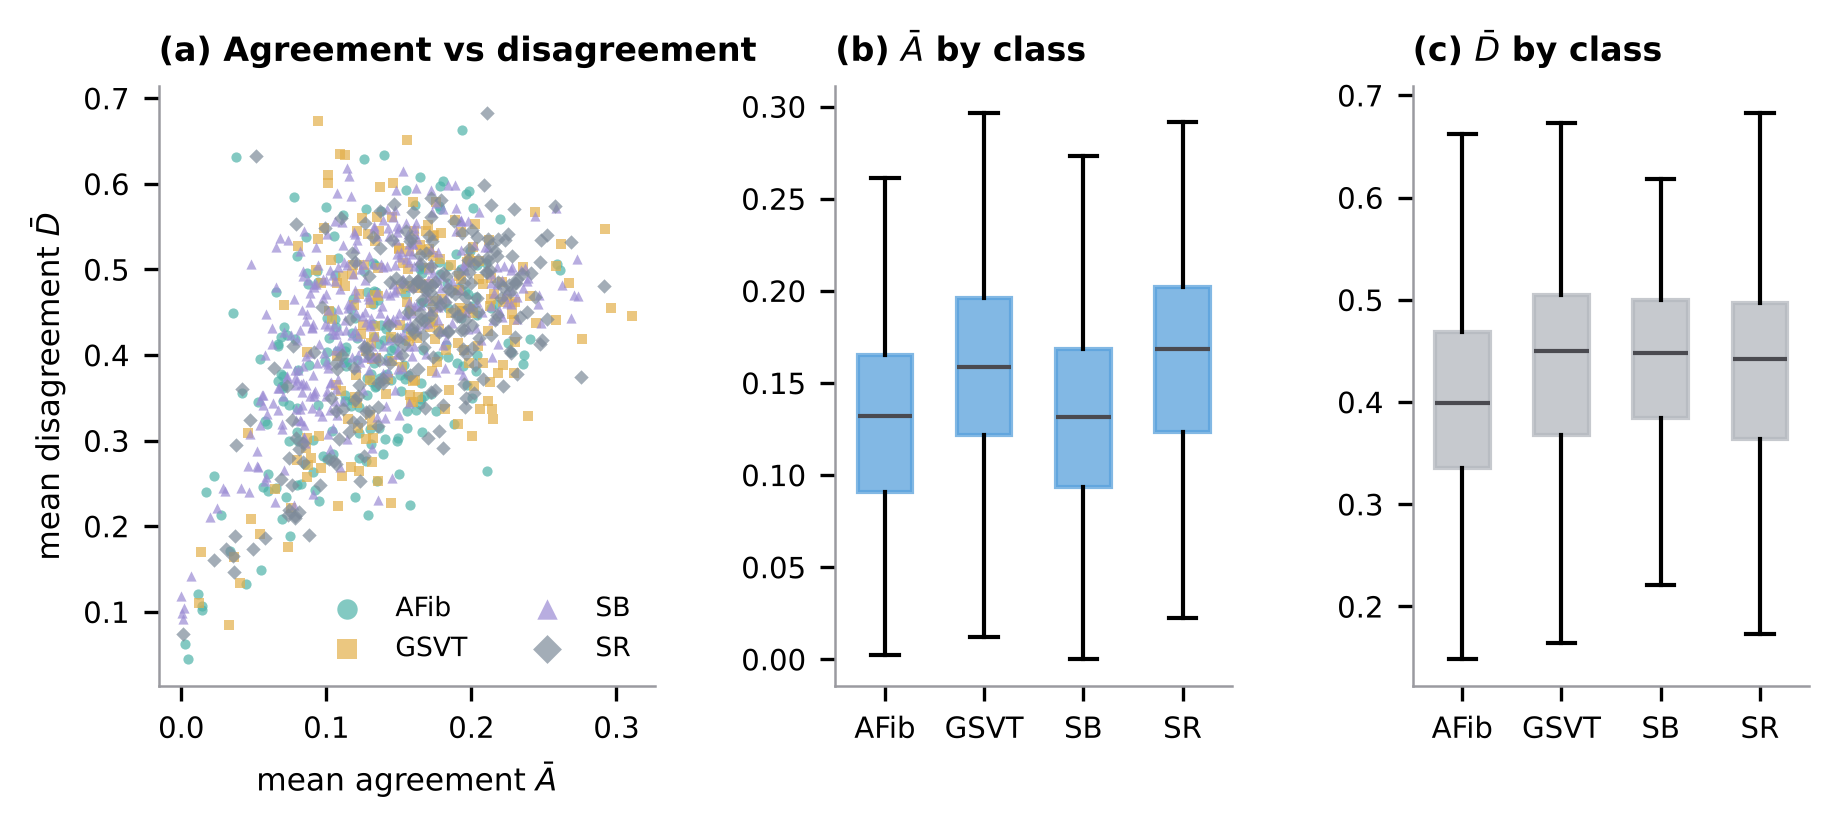

In [8]:
mm = pd.read_csv(ARCH / 'module1/minmax_agreement_shift0.csv')
ok = mm[(mm.degenerate_1d.astype(str) == 'False') & (mm.degenerate_2d.astype(str) == 'False')]
base_cmp = pd.DataFrame({
    'method': ['min–max agreement (Module 1 branch)', 'intensity-aware mass (this work)'],
    'n': [len(ok), len(prim)],
    'median weighted Jaccard': [ok.weighted_jaccard.median(), prim.Jw.median()],
    'median Spearman': [ok.spearman.median(), prim.spearman.median()],
    'median Dice top-15%': [ok.dice_top15.median(), prim.dice15.median()]})
base_cmp.to_csv(TAB / 'module1_baseline_comparison.csv', index=False)
display(base_cmp.round(3))
F.fig_m1_baseline(mm, FIG); show('fig_module1_minmax_baseline', 600)

In [9]:
proj = pd.read_csv(ARCH / 'module1/projection_summary.csv')
print('Sensitivity of the min–max baseline to the corridor half-width (px):')
proj.round(4)

Sensitivity of the min–max baseline to the corridor half-width (px):


,mask_size,mean_agreement,mean_disagreement,spearman,dice_top15,iou_top15,weighted_jaccard
0,6,0.1404,0.4234,0.0862,0.1765,0.0990,0.1561
1,13,0.1406,0.4241,0.0869,0.1769,0.0993,0.1560
2,24,0.1408,0.4250,0.0881,0.1780,0.1000,0.1560


## 5. Module 1 branch analysis: min–max agreement and disagreement (1054 recordings)

The Module 1 branch projects the 2D Grad-CAM with a 13-px vertical maximum-filter mask around the trace (±6 px), min–max normalises both profiles over the valid columns,
and summarises each recording by the mean local agreement $\bar A$, the mean local disagreement $\bar D$, Spearman, top-15 % Dice and IoU, and weighted Jaccard.
A profile with range below $10^{-8}$ is degenerate; similarity metrics use the non-degenerate pairs. The per-recording values were computed by the branch scripts
(`src/hpc_pipeline/02_gradcam_and_module1/module1_alignment_branch/`) and are archived in `data/archived/module1/branch/`; this section recomputes every summary and test from them.

In [10]:
from scipy.stats import kruskal as kw_test, mannwhitneyu
BR = ARCH / 'module1' / 'branch'
m1b = pd.read_csv(BR / 'agreement_metrics_0px.csv')
m1b['degenerate'] = (m1b.degenerate_1d.astype(str) == 'True') | (m1b.degenerate_2d.astype(str) == 'True')
nd = m1b[~m1b.degenerate].copy()
p1r = pd.read_csv(ARCH / 'replication/1d_test_predictions.csv').set_index('cohort_index')
p2r = pd.read_csv(ARCH / 'replication/2d_test_predictions.csv').set_index('cohort_index')
both = (p1r.true_class == p1r.predicted_class) & (p2r.true_class == p2r.predicted_class)
m1b['both_correct'] = m1b.cohort_index.map(both); nd['both_correct'] = nd.cohort_index.map(both)
SIM = ['spearman', 'dice_top15', 'iou_top15', 'weighted_jaccard']
METRICS = ['mean_agreement', 'mean_disagreement'] + SIM
overall = pd.Series({
    'total recordings': len(m1b), 'non-degenerate pairs': len(nd), 'degenerate pairs': int(m1b.degenerate.sum()),
    'both CNNs correct': int(m1b.both_correct.sum()), 'both correct and non-degenerate': int(nd.both_correct.sum()),
    'mean agreement (1054)': m1b.mean_agreement.mean(), 'mean disagreement (1054)': m1b.mean_disagreement.mean(),
    **{f'{k} (1033)': nd[k].mean() for k in SIM}})
overall.to_csv(TAB / 'module1_branch_overall.csv', header=['value'])
overall.round(4).to_frame('value')

,value
total recordings,1054.0000
non-degenerate pairs,1033.0000
degenerate pairs,21.0000
both CNNs correct,980.0000
both correct and non-degenerate,962.0000
mean agreement (1054),0.1406
mean disagreement (1054),0.4241
spearman (1033),0.0869
dice_top15 (1033),0.1769
iou_top15 (1033),0.0993


In [11]:
cls = nd.groupby('class_name')[METRICS].mean(); cls.insert(0, 'n', nd.groupby('class_name').size())
cls.to_csv(TAB / 'module1_branch_classwise.csv')
print('Class-wise means (1033 non-degenerate pairs):')
cls.round(4)

Class-wise means (1033 non-degenerate pairs):


,n,mean_agreement,mean_disagreement,spearman,dice_top15,iou_top15,weighted_jaccard
class_name,,,,,,,
AFib,221,0.1292,0.3952,0.0792,0.1865,0.1055,0.1492
GSVT,203,0.1577,0.4298,0.0508,0.1637,0.0910,0.1714
SB,388,0.1337,0.4359,0.0698,0.1605,0.0892,0.1429
SR,221,0.1615,0.4251,0.1576,0.2082,0.1185,0.1718


In [12]:
rows, pw = [], []
k, n = 4, len(nd)
for mtr in METRICS:
    groups = [nd[nd.class_name == c][mtr] for c in CLASSES]
    H, p = kw_test(*groups)
    rows.append({'metric': mtr, 'H': H, 'p': p, 'epsilon_squared': (H - k + 1) / (n - k)})
    raw = []
    for i in range(4):
        for j in range(i + 1, 4):
            a, b = groups[i], groups[j]
            U, pr = mannwhitneyu(a, b, alternative='two-sided')
            raw.append({'metric': mtr, 'pair': f'{CLASSES[i]}–{CLASSES[j]}', 'U': U, 'p_raw': pr,
                        'rank_biserial': 2 * U / (len(a) * len(b)) - 1})
    order = np.argsort([r['p_raw'] for r in raw]); m = len(raw); prev = 0
    for rank, idx in enumerate(order):                       # Holm step-down over the six class pairs
        adj = min(1.0, max(prev, (m - rank) * raw[idx]['p_raw'])); raw[idx]['p_holm'] = adj; prev = adj
    pw += raw
kwt = pd.DataFrame(rows); pwt = pd.DataFrame(pw); pwt['significant'] = pwt.p_holm < .05
kwt.to_csv(TAB / 'module1_branch_kruskal.csv', index=False); pwt.to_csv(TAB / 'module1_branch_pairwise.csv', index=False)
display(kwt.assign(p=kwt.p.map('{:.2e}'.format)).round(4))
for mtr in ['mean_agreement', 'mean_disagreement']:
    print(f'{mtr}: Holm-significant pairs ->', ', '.join(pwt[(pwt.metric == mtr) & pwt.significant].pair))

,metric,H,p,epsilon_squared
0,mean_agreement,67.6596,1.35e-14,0.0628
1,mean_disagreement,25.9339,9.85e-06,0.0223
2,spearman,108.5275,2.28e-23,0.1026
3,dice_top15,52.3809,2.48e-11,0.0480
4,iou_top15,52.3809,2.48e-11,0.0480
5,weighted_jaccard,63.0465,1.31e-13,0.0584


mean_agreement: Holm-significant pairs -> AFib–GSVT, AFib–SR, GSVT–SB, SB–SR
mean_disagreement: Holm-significant pairs -> AFib–GSVT, AFib–SB, AFib–SR


In [13]:
sub = []
g1, g0 = nd[nd.both_correct], nd[~nd.both_correct]
for mtr in METRICS:
    U, p = mannwhitneyu(g1[mtr], g0[mtr], alternative='two-sided')
    sub.append({'metric': mtr, 'mean both correct': g1[mtr].mean(), 'mean ≥1 wrong': g0[mtr].mean(), 'p': p,
                'rank_biserial': 2 * U / (len(g1) * len(g0)) - 1})
sub = pd.DataFrame(sub); sub.to_csv(TAB / 'module1_branch_correctness.csv', index=False)
print(f'correct in both CNNs: {len(g1)} | misclassified by at least one: {len(g0)}  (exploratory, no multiplicity correction)')
sub.assign(p=sub.p.map('{:.2e}'.format)).round(4)

correct in both CNNs: 962 | misclassified by at least one: 71  (exploratory, no multiplicity correction)


,metric,mean both correct,mean ≥1 wrong,p,rank_biserial
0,mean_agreement,0.1493,0.0636,7.58e-31,0.8203
1,mean_disagreement,0.4336,0.2899,7.23e-19,0.6302
2,spearman,0.0905,0.0374,3.86e-04,0.2521
3,dice_top15,0.1762,0.1859,3.63e-01,-0.0646
4,iou_top15,0.0989,0.1052,3.63e-01,-0.0646
5,weighted_jaccard,0.1596,0.1076,1.22e-11,0.4815


saved col_module1_classwise


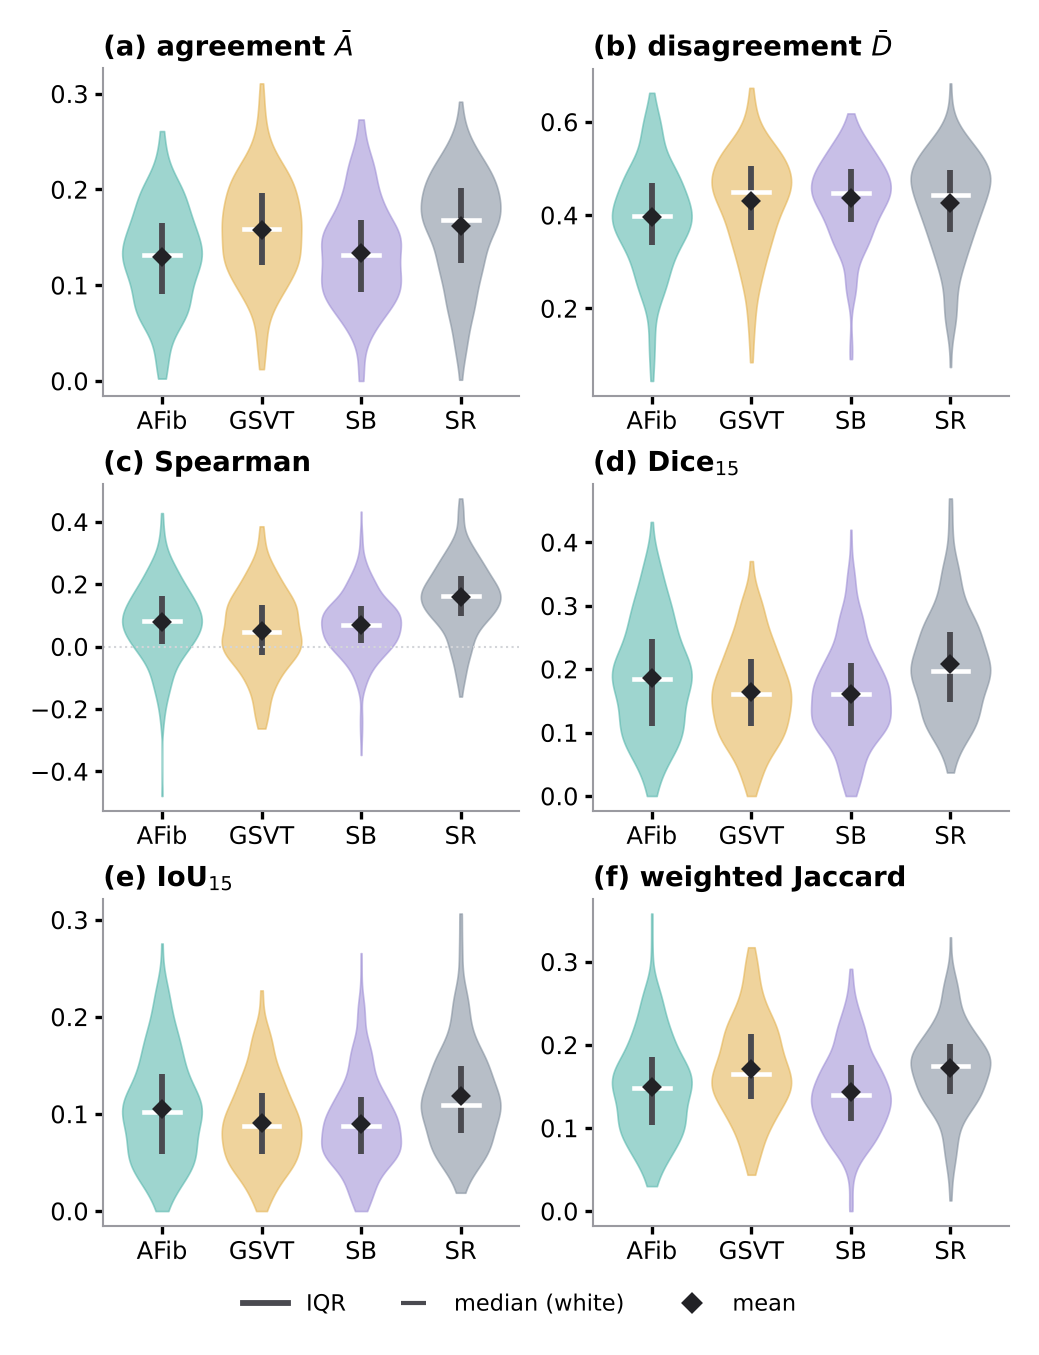

In [14]:
import dan_column_figures as C
C.fig_module1_classwise_column(nd, FIG)
show('col_module1_classwise', 420)

### 5.1 Sensitivity: temporal shift, projection mask and independent alignment validation

,shift −5…+5 px: min,shift: max,mask 6/13/24 px: min,mask: max
mean_agreement,0.1388,0.1422,0.1404,0.1408
mean_disagreement,0.4226,0.4263,0.4234,0.4250
spearman,0.0413,0.1265,0.0862,0.0881
dice_top15,0.1704,0.1827,0.1765,0.1780
iou_top15,0.0954,0.1027,0.0990,0.1000
weighted_jaccard,0.1537,0.1579,0.1560,0.1561


Spearman at shift −5 / 0 / +5 px: [0.1265, 0.0869, 0.0413]
saved col_module1_sensitivity


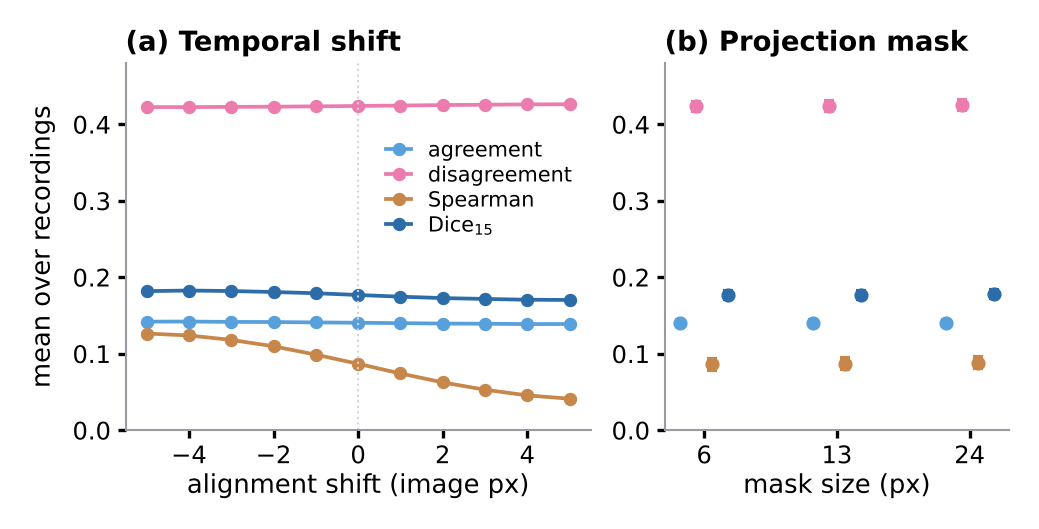

In [15]:
sh = pd.read_csv(BR / 'shift_metrics.csv')
sh_nd = sh[(sh.degenerate_1d.astype(str) == 'False') & (sh.degenerate_2d.astype(str) == 'False')]
shift_summary = pd.concat([sh.groupby('shift_pixels')[['mean_agreement', 'mean_disagreement']].mean(),
                           sh_nd.groupby('shift_pixels')[SIM].mean()], axis=1)
shift_summary.to_csv(TAB / 'module1_branch_shift_sensitivity.csv')
pr = pd.read_csv(BR / 'projection_metrics.csv')
rng42 = np.random.default_rng(42); boot = []
for mask_size, g in pr.groupby('mask_size'):
    gnd = g[(g.degenerate_1d.astype(str) == 'False') & (g.degenerate_2d.astype(str) == 'False')]
    for mtr in METRICS:
        v = (g if mtr in ('mean_agreement', 'mean_disagreement') else gnd)[mtr].to_numpy()
        b = v[rng42.integers(len(v), size=(2000, len(v)))].mean(1)
        boot.append({'mask_size': mask_size, 'metric': mtr, 'mean': v.mean(), 'ci_lo': np.percentile(b, 2.5), 'ci_hi': np.percentile(b, 97.5)})
proj_boot = pd.DataFrame(boot); proj_boot.to_csv(TAB / 'module1_branch_projection_sensitivity.csv', index=False)
rngs = pd.DataFrame({'shift −5…+5 px: min': shift_summary.min(), 'shift: max': shift_summary.max(),
                     'mask 6/13/24 px: min': proj_boot.pivot(index='mask_size', columns='metric', values='mean').min(),
                     'mask: max': proj_boot.pivot(index='mask_size', columns='metric', values='mean').max()})
display(rngs.loc[METRICS].round(4))
print('Spearman at shift −5 / 0 / +5 px:', shift_summary.spearman.loc[[-5, 0, 5]].round(4).tolist())
C.fig_module1_sensitivity_column(shift_summary, proj_boot, FIG)
show('col_module1_sensitivity', 420)

In [16]:
tv = pd.read_csv(BR / 'temporal_validation_100.csv')
tvs = tv[['zero_shift_correlation', 'best_correlation', 'correlation_improvement']].agg(['mean', 'median', 'std']).T
tvs.to_csv(TAB / 'module1_branch_temporal_validation.csv')
print(f'recordings: {len(tv)} | selected shift: ' + ', '.join(f'{s:+d} px ({n} ECGs)' for s, n in tv.best_shift_pixels.value_counts().items())
      + f' | {tv.best_shift_ms.mean():.2f} ms')
tvs.round(4)

recordings: 100 | selected shift: +1 px (100 ECGs) | 10.38 ms


,mean,median,std
zero_shift_correlation,0.6585,0.6745,0.1318
best_correlation,0.7916,0.8387,0.1388
correlation_improvement,0.1332,0.1289,0.0633


**Summary of Module 1.** Cross-representation agreement is weak and only marginally above the mispairing null, the 2D explanation is broad,
and disagreement is directional rather than random. This is the evidence that a fused map cannot be read as "both models looked here" without testing.